In [1]:
import marimo as mo

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [3]:
from kaggle_api import fetch_dataset

df_train, df_test = fetch_dataset()

✅ data loaded!


# model overview

- type - logistic regression
    - implemented as a GLM under a Binomial family
- predictor selection method - manual

In [4]:
cols_categorical = "x4 x5 x10 Y".split()

df_train["Y"] = df_train["Y"].astype("category")

for df in (df_train, df_test):
    for _col in cols_categorical[:-1]:
        df[_col] = df[_col].astype("category")

    df["x1a"] = (df.x1 >= 0).astype(np.int8).astype("category")

In [5]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

_model = smf.glm(
    "Y ~ x1 + x2 + x3 + x4 + x5 + x6 + x7 + x8 + x9 + x10 + x1a",
    data=df_train,
    family=sm.families.Binomial(),
).fit()

_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:       ['Y[0]', 'Y[1]']   No. Observations:                15000
Model:                            GLM   Df Residuals:                    14985
Model Family:                Binomial   Df Model:                           14
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -8056.6
Date:                Thu, 19 Nov 2026   Deviance:                       16113.
Time:                        22:08:38   Pearson chi2:                 1.49e+04
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1026
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.8528      0.062     29.852      0.000       1.731       1.974
x4[T.1]        0.0745      0.039      1.933      0.053      -0.001       0.150
x5[T.1]       -0.0281      0.045     -0.621      0.535      -0.117       0.061
x5[T.2]       -0.2772      0.048     -5.753      0.000      -0.372      -0.183
x10[T.1]       0.0408      0.055      0.739      0.460      -0.067       0.149
x10[T.2]      -0.0496      0.055     -0.906      0.365      -0.157       0.058
x10[T.3]      -0.0526      0.054     -0.971      0.331      -0.159       0.054
x1a[T.1]      -1.3856      0.066    -21.152      0.000      -1.514      -1.257
x1            -0.0451      0.039     -1.163      0.245      -0.121       0.031
x2            -0.1521      0.019     -7.860      0.000      -0.190      -0.114
x3             0.0751      0.014      5.301      0.000       0.047       0.103
x6            -0.0804      0.019     -4.124      0.000      -0.119      -0.042
x7            -0.1788      0.019     -9.251      0.000      -0.217      -0.141
x8             0.0058      0.019      0.301      0.764      -0.032       0.043
x9            -0.0030      0.029     -0.103      0.918      -0.060       0.054
==============================================================================
"""

now we remove the insignificant ones ($x_{10}, x_1, x_8, x_9$):

TODO use forward-backward-lasso to select parameters instead

In [6]:
model = smf.glm(
    "Y ~ x2 + x3 + x4 + x5 + x6 + x7 + x1a",
    data=df_train,
    family=sm.families.Binomial(),
).fit()

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:       ['Y[0]', 'Y[1]']   No. Observations:                15000
Model:                            GLM   Df Residuals:                    14991
Model Family:                Binomial   Df Model:                            8
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -8059.7
Date:                Thu, 19 Nov 2026   Deviance:                       16119.
Time:                        22:08:38   Pearson chi2:                 1.49e+04
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1023
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.8721      0.046     41.063      0.000       1.783       1.961
x4[T.1]        0.0756      0.039      1.961      0.050     3.6e-05       0.151
x5[T.1]       -0.0278      0.045     -0.614      0.539      -0.116       0.061
x5[T.2]       -0.2771      0.048     -5.755      0.000      -0.371      -0.183
x1a[T.1]      -1.4593      0.041    -35.501      0.000      -1.540      -1.379
x2            -0.1518      0.019     -7.843      0.000      -0.190      -0.114
x3             0.0751      0.014      5.298      0.000       0.047       0.103
x6            -0.0808      0.019     -4.145      0.000      -0.119      -0.043
x7            -0.1787      0.019     -9.255      0.000      -0.217      -0.141
==============================================================================
"""

In [7]:
prediction = model.get_prediction(df_test)

prediction_probs = pd.Series(prediction.predicted, index=df_test.index)

# model assessment

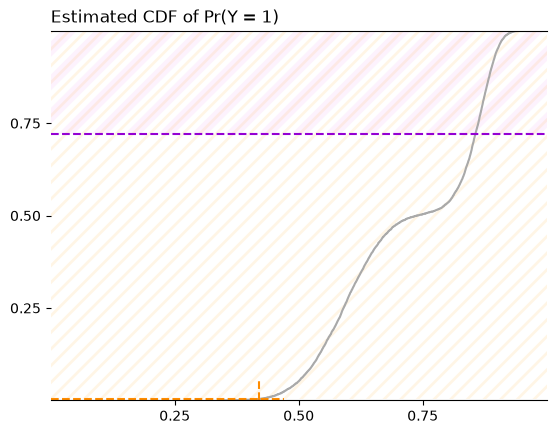

In [8]:
import threshold as th

pos_prediction_count, threshold = th.estimate_optimal_threshold(prediction_probs)

mo.output.append(pos_prediction_count)
mo.output.append(threshold)

mo.output.append(
    th.plot_probs(
        probs=prediction_probs,
        expt_prob=np.mean(df_train.Y.astype(np.int64)),
        threshold=threshold,
        pos_pred_count=pos_prediction_count,
    )
)

<Axes: title={'left': 'Comparison of F-scores'}>

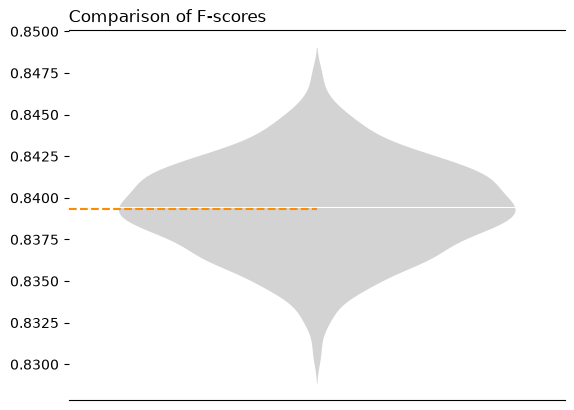

In [9]:
rng = np.random.default_rng(1)

th.plot_f_scores(
    empiricals=th.sample_probable_f_scores(
        rng, 1000, prediction_probs, pos_prediction_count
    ),
    calculated=2 * threshold,
    reported=None,
)

# make submission

In [10]:
predictions = prediction_probs.sort_values(ascending=False)
predictions.iloc[0:pos_prediction_count] = 1
predictions.iloc[pos_prediction_count:] = 0
predictions = predictions.astype(np.int8).sort_index()

predictions

ID
15001    1
15002    1
15003    1
15004    1
15005    1
        ..
24996    1
24997    1
24998    1
24999    1
25000    1
Length: 10000, dtype: int8

In [11]:
import os
import os.path
import pathlib

notebook_path = os.environ.get("JPY_SESSION_NAME")
submission_filepath = pathlib.Path(
    f"./submissions/{os.path.splitext(os.path.basename(notebook_path))[0]}.csv"
)
print(f"saving submission file to {submission_filepath}")
predictions.to_csv(submission_filepath)

saving submission file to submissions/model2_glm_bin_234567b.csv
